<a href="https://colab.research.google.com/github/valentinajuliette/reconocimiento-de-perros-con-IA/blob/main/ProyectoIA_Perritos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto de reconocimiento de perros con IA
Desarrollé un modelo híbrido (Detector YOLOv8 para recortar el perro + Extractor ConvNeXt + Similitud Coseno).




> Versión: 1.1




## Instalación de dependencias y montaje de Google Drive

In [2]:
# 1. Instalar librerías necesarias
!pip install -q ultralytics scikit-learn seaborn matplotlib torchvision tqdm

# 2. Montar Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Configuración de rutas y pipeline idéntico al backend

In [3]:
import os
import random
import unicodedata
from collections import defaultdict
import numpy as np
from PIL import Image, ImageOps
import torch
import torchvision.models as models
import torchvision.transforms as transforms
from ultralytics import YOLO
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

# --- AJUSTA AQUÍ LA RUTA A TU CARPETA EN DRIVE ---
DATASET_PATH = "/content/drive/MyDrive/GUAUrdados/db_perros"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo de ejecución: {device}")

# Carga de modelos exactamente iguales a main.py
detector = YOLO("yolov8n.pt")

transform = transforms.Compose([
    transforms.Resize((236, 236)),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]
    ),
])

feature_extractor = models.convnext_small(
    weights=models.ConvNeXt_Small_Weights.DEFAULT
)
feature_extractor.classifier[2] = torch.nn.Identity()
feature_extractor = feature_extractor.to(device).eval()

def normalizar_texto(texto: str) -> str:
    texto = unicodedata.normalize("NFD", texto.lower())
    return "".join(c for c in texto if unicodedata.category(c) != "Mn").strip()

def corregir_orientacion(img: Image.Image) -> Image.Image:
    try:
        return ImageOps.exif_transpose(img)
    except Exception:
        return img

def recortar_perro_desde_pil(img: Image.Image):
    img = corregir_orientacion(img).convert("RGB")
    results = detector(img, verbose=False)[0]
    dog_boxes = [box for box in results.boxes if int(box.cls[0]) == 16]

    if not dog_boxes:
        return None

    best_box = max(dog_boxes, key=lambda b: float(b.conf[0]))
    x1, y1, x2, y2 = map(int, best_box.xyxy[0].tolist())

    ancho, alto = img.size
    dx = int((x2 - x1) * 0.1)
    dy = int((y2 - y1) * 0.1)

    nx1 = max(0, x1 - dx)
    ny1 = max(0, y1 - dy)
    nx2 = min(ancho, x2 + dx)
    ny2 = min(alto, y2 + dy)

    return img.crop((nx1, ny1, nx2, ny2))

def obtener_embedding(pil_img: Image.Image) -> np.ndarray:
    pil_img = corregir_orientacion(pil_img).convert("RGB")
    tensor_img = transform(pil_img).unsqueeze(0).to(device)
    with torch.no_grad():
        embedding = feature_extractor(tensor_img)
    embedding = embedding / torch.norm(embedding, p=2, dim=1, keepdim=True)
    return embedding.cpu().numpy().flatten()

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Dispositivo de ejecución: cuda
Downloading: "https://download.pytorch.org/models/convnext_small-0c510722.pth" to /root/.cache/torch/hub/checkpoints/convnext_small-0c510722.pth


100%|██████████| 192M/192M [00:03<00:00, 64.5MB/s]


## Partición estratificada (70% Gallery / 15% Val / 15% Test)

In [4]:
random.seed(42)
IMG_EXTENSIONS = (".jpg", ".jpeg", ".png", ".webp")

perros_dict = defaultdict(list)
for perro_folder in os.listdir(DATASET_PATH):
    perro_path = os.path.join(DATASET_PATH, perro_folder)
    if not os.path.isdir(perro_path):
        continue
    fotos = [
        os.path.join(perro_path, f)
        for f in os.listdir(perro_path)
        if f.lower().endswith(IMG_EXTENSIONS)
    ]
    if fotos:
        perros_dict[perro_folder] = fotos

train_gallery = {}
val_queries = []
test_queries = []

print("Resumen de partición por perro:")
for perro, fotos in perros_dict.items():
    random.shuffle(fotos)
    n = len(fotos)

    # Si un perro tiene menos de 3 fotos, al menos 1 queda en galería
    n_train = max(1, int(n * 0.70))
    n_val = max(1, int(n * 0.15)) if n >= 3 else 0

    train_fotos = fotos[:n_train]
    val_fotos = fotos[n_train:n_train + n_val]
    test_fotos = fotos[n_train + n_val:]

    train_gallery[perro] = train_fotos
    for f in val_fotos:
        val_queries.append((f, perro))
    for f in test_fotos:
        test_queries.append((f, perro))

    print(f" - {perro}: Total={n} | Train/Gallery={len(train_fotos)}, Val={len(val_fotos)}, Test={len(test_fotos)}")

print(f"\nTotal imágenes de prueba (Test): {len(test_queries)}")

Resumen de partición por perro:
 - Ramona: Total=16 | Train/Gallery=11, Val=2, Test=3
 - Bobby: Total=16 | Train/Gallery=11, Val=2, Test=3
 - Perla: Total=23 | Train/Gallery=16, Val=3, Test=4
 - Amada: Total=61 | Train/Gallery=42, Val=9, Test=10
 - Cabezón: Total=21 | Train/Gallery=14, Val=3, Test=4
 - Romeo: Total=18 | Train/Gallery=12, Val=2, Test=4
 - Lobito: Total=10 | Train/Gallery=7, Val=1, Test=2
 - Mora: Total=10 | Train/Gallery=7, Val=1, Test=2
 - Tommy: Total=18 | Train/Gallery=12, Val=2, Test=4
 - Ramón : Total=31 | Train/Gallery=21, Val=4, Test=6

Total imágenes de prueba (Test): 42


## Extracción e indexación de embeddings de la Galería (Train)

In [5]:
base_embeddings = {}

print("Extrayendo embeddings del conjunto de entrenamiento...")
for perro, fotos in tqdm(train_gallery.items()):
    vectores = []
    for foto_path in fotos:
        try:
            img = Image.open(foto_path)
            recorte = recortar_perro_desde_pil(img)
            img_final = recorte if recorte is not None else corregir_orientacion(img).convert("RGB")
            emb = obtener_embedding(img_final)
            vectores.append(emb)
        except Exception as e:
            print(f"Error procesando {foto_path}: {e}")
    if vectores:
        base_embeddings[perro] = np.array(vectores)

clases_unicas = sorted(list(base_embeddings.keys()))
print(f"\nIndexación terminada. Clases disponibles: {len(clases_unicas)}")

Extrayendo embeddings del conjunto de entrenamiento...


100%|██████████| 10/10 [01:47<00:00, 10.71s/it]


Indexación terminada. Clases disponibles: 10


## Inferencia y simulación de la lógica de umbrales de GUAUrdados
Establecí una lógica de umbrales:
- MATCH: 0.5% y diferencia entre primer y segundo match superior al 10%.
- AMBIGUOUS: Puntaje de coincidencia mayor a 0.5% pero diferencia entre primer y segundo match menor al 10%.
- NO MATCH: Puntaje de coincidencia inferior al 0.5% en el Top-1.

En los casos de MATCH y NO MATCH, se entrega el resultado directo; y en el caso AMBIGUOUS, se sugieren los 2 match con mayor coincidencia y solicita confirmación del usuario.

Esto busca evitar falsos positivos, lo cual es ideal para un sistema donde asegurar la identidad correcta del perrito es crucial.

In [6]:
from sklearn.metrics.pairwise import cosine_similarity

def evaluar_imagen(foto_path: str):
    img = Image.open(foto_path)
    recorte = recortar_perro_desde_pil(img)
    img_eval = recorte if recorte is not None else corregir_orientacion(img).convert("RGB")
    query_vec = obtener_embedding(img_eval).reshape(1, -1)

    candidatos = []
    for perro, mat_vectores in base_embeddings.items():
        similitudes = cosine_similarity(query_vec, mat_vectores)[0]
        max_score = float(np.max(similitudes))
        candidatos.append({"perro": perro, "score": max_score})

    candidatos.sort(key=lambda x: x["score"], reverse=True)
    top1 = candidatos[0]
    score1 = top1["score"]

    if score1 < 0.5:
        return "NO_MATCH", top1["perro"], score1, None

    if len(candidatos) == 1:
        return "MATCH", top1["perro"], score1, None

    top2 = candidatos[1]
    score2 = top2["score"]
    diferencia = (score1 - score2) * 100

    if diferencia >= 10.0:
        return "MATCH", top1["perro"], score1, diferencia
    elif 0.1 <= diferencia < 10.0:
        return "AMBIGUOUS", top1["perro"], score1, diferencia
    else:
        return "NO_MATCH", top1["perro"], score1, diferencia

# Evaluación sobre el conjunto de test
y_true = []
y_pred_top1 = []       # Predicción directa por similitud máxima (sin filtros de negocio)
y_pred_sistema = []    # Predicción aplicando las reglas MATCH / AMBIGUOUS / NO_MATCH
resultados_metadata = []

print("Evaluando conjunto de Test...")
for foto_path, ground_truth in tqdm(test_queries):
    status, pred_perro, score, diff = evaluar_imagen(foto_path)

    y_true.append(ground_truth)
    y_pred_top1.append(pred_perro)

    # En la lógica de negocio, si no hay certeza o es ambiguo, se clasifica como abstención
    if status == "MATCH":
        y_pred_sistema.append(pred_perro)
    else:
        y_pred_sistema.append("NO_MATCH_O_AMBIGUO")

    resultados_metadata.append({
        "path": foto_path,
        "true": ground_truth,
        "pred": pred_perro,
        "status": status,
        "score": score,
        "diff": diff
    })

Evaluando conjunto de Test...


100%|██████████| 42/42 [00:27<00:00,  1.51it/s]


## Reporte de métricas y Matriz de Confusión


ACCURACY PURA DEL EXTRACTOR (TOP-1): 92.86%

Distribución de decisiones:
 - MATCH (Aceptados con certeza): 27 (64.3%)
 - AMBIGUOUS (Requiere revisión humana): 14 (33.3%)
 - NO_MATCH (Rechazados por baja confianza/empate): 1 (2.4%)

Precisión efectiva en casos MATCH: 100.00% (27/27)

INFORME DE CLASIFICACIÓN DETALLADO (Top-1 Feature Extractor)
              precision    recall  f1-score   support

       Amada       1.00      1.00      1.00        10
       Bobby       1.00      1.00      1.00         3
    Cabezón       0.80      1.00      0.89         4
      Lobito       1.00      1.00      1.00         2
        Mora       1.00      0.50      0.67         2
       Perla       1.00      1.00      1.00         4
      Ramona       1.00      0.67      0.80         3
     Ramón        0.75      1.00      0.86         6
       Romeo       1.00      1.00      1.00         4
       Tommy       1.00      0.75      0.86         4

    accuracy                           0.93        42
   ma

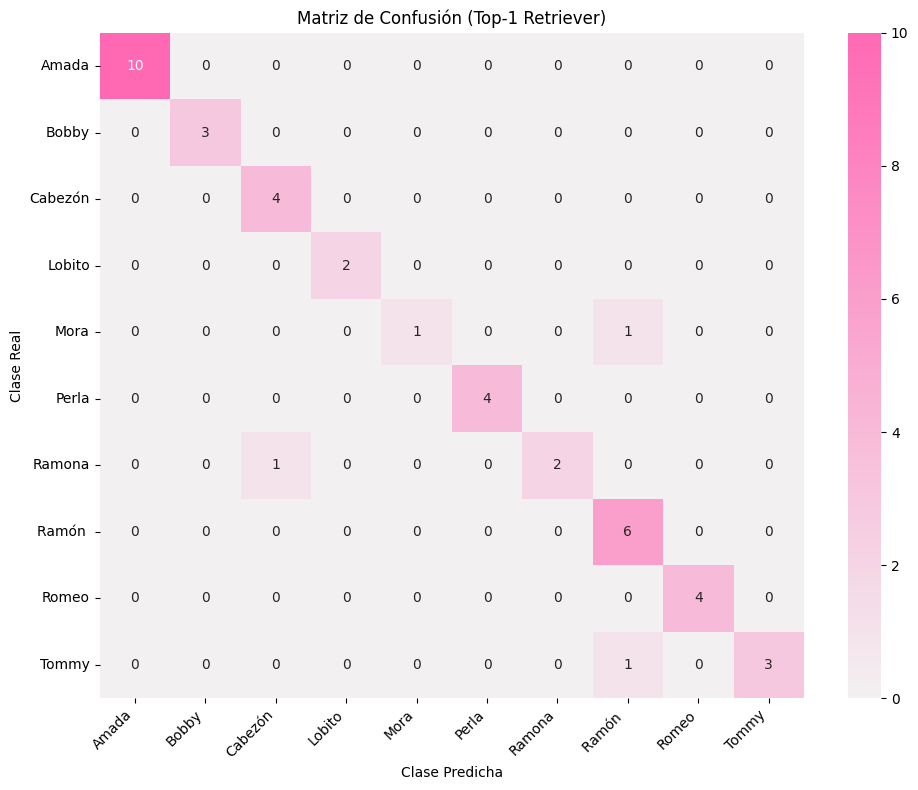

In [10]:
# 1. Métricas brutas del extractor (Accuracy Top-1 puro sin rechazo)
acc_top1 = accuracy_score(y_true, y_pred_top1)
print("=" * 60)
print(f"ACCURACY PURA DEL EXTRACTOR (TOP-1): {acc_top1 * 100:.2f}%")
print("=" * 60)

# 2. Desglose de estados del sistema de decisión
estados = [r["status"] for r in resultados_metadata]
total_evals = len(estados)
print(f"\nDistribución de decisiones:")
print(f" - MATCH (Aceptados con certeza): {estados.count('MATCH')} ({estados.count('MATCH')/total_evals*100:.1f}%)")
print(f" - AMBIGUOUS (Requiere revisión humana): {estados.count('AMBIGUOUS')} ({estados.count('AMBIGUOUS')/total_evals*100:.1f}%)")
print(f" - NO_MATCH (Rechazados por baja confianza/empate): {estados.count('NO_MATCH')} ({estados.count('NO_MATCH')/total_evals*100:.1f}%)")

# 3. Precisión de las alertas aceptadas (Cuando el sistema dice MATCH, ¿cuántas veces acierta?)
matches_correctos = sum(1 for r in resultados_metadata if r["status"] == "MATCH" and r["true"] == r["pred"])
total_matches = estados.count("MATCH")
precision_match = (matches_correctos / total_matches * 100) if total_matches > 0 else 0
print(f"\nPrecisión efectiva en casos MATCH: {precision_match:.2f}% ({matches_correctos}/{total_matches})")

# 4. Reporte detallado (Precision, Recall, F1-Score por perro)
print("\n" + "=" * 60)
print("INFORME DE CLASIFICACIÓN DETALLADO (Top-1 Feature Extractor)")
print("=" * 60)
print(classification_report(y_true, y_pred_top1, zero_division=0))

# 5. Visualización de Matriz de Confusión
cm = confusion_matrix(y_true, y_pred_top1, labels=clases_unicas)

# Genera una paleta secuencial perfecta partiendo de un rosa intenso
pink_cmap = sns.light_palette("#FF69B4", as_cmap=True)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap=pink_cmap,
    xticklabels=clases_unicas,
    yticklabels=clases_unicas
)
plt.title("Matriz de Confusión (Top-1 Retriever)")
plt.xlabel("Clase Predicha")
plt.ylabel("Clase Real")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Breve introducción a las métricas de evaluación ;)
### Sobre el Top-1 Feature Extractor:
- **Feature Extractor (Extractor de características):** Es un modelo de Inteligencia Artificial profunda (en este caso, un codificador visual llamado `ConvNeXt`) que toma una imagen y la traduce en un vector numérico largo (el `embedding`). Este vector representa las características visuales clave de la foto (forma de la cabeza, ojos, textura del pelo, color, etc.).
- **Top-1:** Significa que para identificar al perro, tomamos la **primera opción más similar** (la que obtuvo el puntaje de similitud de coseno más alto). Si la opción con mayor coincidencia es la correcta, se cuenta como un acierto. No se permiten segundas oportunidades (eso sería un *Top-2* o *Top-5*).
- En resumen, **Top-1 Feature Extractor** es la precisión directa de mi modelo buscando únicamente la coincidencia más fuerte en tu base de datos, sin aplicar todavía ningún filtro de seguridad o reglas de negocio.

### Diferencia entre Precision, Recall, F1-Score y Support
- *Precision (Precisión - ¿Qué tan confiable es cuando dice que es un perro específico?):* Si el sistema dice "¡Esta foto es de Ramona!", ¿qué tan seguro es de que realmente sea ella?

  - Ejemplo: Si el modelo predice 10 veces que el perro es "Ramón" pero solo 6 eran realmente Ramón, la precisión baja. En este caso, Amada tiene 1.00 de precisión; esto significa que cada vez que el sistema dijo "es Amada", siempre acertó.

- *Recall (Sensibilidad o Cobertura - ¿Cuántos de los casos reales logró encontrar?):* De todas las fotos reales que hay de Ramona en el set de prueba, ¿cuántas logró identificar el sistema?

  - Ejemplo: Si hay 2 fotos de Mora en el set de prueba (support = 2), pero el sistema solo identificó correctamente 1 (recall = 0.50), significa que se le escapó la mitad de las fotos reales de Mora.

- **F1-Score:** Es el promedio "armonioso" entre la Precision y el Recall. Nos da una única métrica balanceada para saber qué tan bien funciona el modelo para cada perro de manera justa (evitando que un modelo sea muy preciso pero no encuentre casi nada, o que encuentre todo pero se equivoque constantemente).

- **Support (Soporte):** Es simplemente la cantidad de imágenes reales de ese perro que había en tu conjunto de prueba (Test). Por ejemplo, de Amada había 10 fotos, de Ramona había 3 y de Lobito 2.

## Análisis de resultados
- Precisión general (Accuracy) de 92.86%: de las 42 fotos de prueba que el modelo nunca había visto, el extractor de características identificó correctamente la clase en 39 ocasiones (92.86% de éxito puro). Para un problema de 10 clases con fotos que varían en luz, rotación y pose, es un rendimiento excelente.

- La regla de seguridad (MATCH) es 100% infalible: el código aplica un filtro inteligente que solo aprueba la predicción como MATCH (con certeza absoluta) si la diferencia de similitud entre el primer lugar y el segundo es mayor o igual al 10%.

  - Aplicando esta regla, el sistema tomó la decisión de dar un veredicto firme en el 64.3% de los casos (27 fotos).
  - Lo más importante: ¡La precisión efectiva en estos casos fue del 100%! (27 de 27 aciertos). Esto significa que el sistema nunca le entregará una alerta confirmada falsa al usuario. Si dice que es un perro con certeza, es ese perro.

  - El rol de las alertas AMBIGUOUS y NO_MATCH: un 33.3% (14 fotos) se clasificaron como AMBIGUOUS y un 2.4% (1 foto) como NO_MATCH. Esto no significa que el extractor no sólo mantuvo su precisión pura del 92.86% sino que también logró reducir el porcentaje de fotos sin match. Lo que significa que en esas fotos donde las características eran muy parecidas a las de otro perro (por ejemplo, por pose o fondo) o la similitud no era lo suficientemente contundente, el sistema sugiere de manera efectiva las dos opciones más probables antes de pedir confirmación humana (AMBIGUOUS), reduciendo significamente el error general del modelo.

- Análisis de la Matriz de Confusión: si observamos la diagonal de la matriz de confusión, veremos que la gran mayoría de las fotos caen en la diagonal (predicciones correctas):

  - Amada (10/10), Bobby (3/3), Cabezón (4/4), Lobito (2/2), Perla (4/4) y Romeo (4/4) se identificaron a la perfección.

- Los pequeños errores: una foto de Mora se confundió con Ramón (comprensible si tienen colores de pelaje o formas similares en la foto).
Una foto de Ramona se confundió con Cabezón.
Una foto de Tommy se confundió con Ramón.


---



## Análisis de casos ambiguos
Este código buscará en las predicciones guardadas, extraerá el puntaje de similitud del primer lugar (el ganador) y del segundo lugar, y nos mostrará exactamente qué dos perritos compitieron tan de cerca en el extractor de características.

In [11]:
import pandas as pd

# Filtramos los resultados clasificados como AMBIGUOUS
casos_ambiguos = [r for r in resultados_metadata if r["status"] == "AMBIGUOUS"]

print(f"Se encontraron {len(casos_ambiguos)} casos marcados como AMBIGUOUS:\n")

detalles_ambiguos = []
for i, caso in enumerate(casos_ambiguos):
    # Re-evaluamos u obtenemos directamente los candidatos para mostrar el top 2 detallado
    foto_path = caso["path"]
    true_label = caso["true"]
    pred_label = caso["pred"]
    score1 = caso["score"]
    diff = caso["diff"]

    # Para obtener el segundo lugar exacto para este reporte
    img = Image.open(foto_path)
    recorte = recortar_perro_desde_pil(img)
    img_eval = recorte if recorte is not None else corregir_orientacion(img).convert("RGB")
    query_vec = obtener_embedding(img_eval).reshape(1, -1)

    candidatos = []
    for perro, mat_vectores in base_embeddings.items():
        similitudes = cosine_similarity(query_vec, mat_vectores)[0]
        max_score = float(np.max(similitudes))
        candidatos.append({"perro": perro, "score": max_score})

    candidatos.sort(key=lambda x: x["score"], reverse=True)

    segundo_perro = candidatos[1]["perro"] if len(candidatos) > 1 else "N/A"
    segundo_score = candidatos[1]["score"] if len(candidatos) > 1 else 0.0

    detalles_ambiguos.append({
        "Archivo": os.path.basename(foto_path),
        "Clase Real": true_label,
        "1° Lugar (Pred)": pred_label,
        "Score 1": round(score1, 4),
        "2° Lugar": segundo_perro,
        "Score 2": round(segundo_score, 4),
        "Diferencia (%)": round(diff, 2)
    })

df_ambiguos = pd.DataFrame(detalles_ambiguos)
display(df_ambiguos)

Se encontraron 14 casos marcados como AMBIGUOUS:



,Archivo,Clase Real,1° Lugar (Pred),Score 1,2° Lugar,Score 2,Diferencia (%)
0,IMG-20260721-WA0036.jpg,Ramona,Ramona,0.6598,Ramón,0.6291,3.07
1,4.png,Ramona,Cabezón,0.6909,Ramona,0.6712,1.97
2,2.jpg,Perla,Perla,0.8527,Cabezón,0.7934,5.93
3,IMG_20261014_171232.jpg,Cabezón,Cabezón,0.7567,Perla,0.6697,8.70
4,IMG-20260512-WA0007.jpg,Cabezón,Cabezón,0.7562,Perla,0.7308,2.54
5,cab1.jpeg,Cabezón,Cabezón,0.8833,Perla,0.7909,9.23
6,IMG-20261015-WA0046.jpg,Romeo,Romeo,0.6338,Ramona,0.5868,4.70
7,IMG-20260619-WA0041.jpg,Tommy,Ramón,0.6633,Ramona,0.6312,3.21
8,IMG-20260627-WA0009.jpg,Ramón,Ramón,0.7367,Ramona,0.6577,7.90
9,IMG-20260805-WA0013.jpg,Ramón,Ramón,0.8545,Ramona,0.7611,9.34


## Análisis de casos sin match
Las imágenes clasificadas como NO_MATCH son aquellas que fueron rechazadas por tener una confianza muy baja o por un empate muy cerrado de similitud, menor al 10%.
Con este código podremos ver cuáles son los perritos que compitieron por el primer lugar y causaron la duda.

In [12]:
import pandas as pd

# Filtramos los resultados clasificados como NO_MATCH
casos_no_match = [r for r in resultados_metadata if r["status"] == "NO_MATCH"]

print(f"Se encontraron {len(casos_no_match)} casos marcados como NO_MATCH:\n")

detalles_no_match = []
for i, caso in enumerate(casos_no_match):
    foto_path = caso["path"]
    true_label = caso["true"]
    pred_label = caso["pred"]
    score1 = caso["score"]
    diff = caso["diff"]

    # Re-extraemos los candidatos para conocer el segundo lugar
    img = Image.open(foto_path)
    recorte = recortar_perro_desde_pil(img)
    img_eval = recorte if recorte is not None else corregir_orientacion(img).convert("RGB")
    query_vec = obtener_embedding(img_eval).reshape(1, -1)

    candidatos = []
    for perro, mat_vectores in base_embeddings.items():
        similitudes = cosine_similarity(query_vec, mat_vectores)[0]
        max_score = float(np.max(similitudes))
        candidatos.append({"perro": perro, "score": max_score})

    candidatos.sort(key=lambda x: x["score"], reverse=True)

    segundo_perro = candidatos[1]["perro"] if len(candidatos) > 1 else "N/A"
    segundo_score = candidatos[1]["score"] if len(candidatos) > 1 else 0.0

    detalles_no_match.append({
        "Archivo": os.path.basename(foto_path),
        "Clase Real": true_label,
        "1° Lugar (Pred)": pred_label,
        "Score 1": round(score1, 4),
        "2° Lugar": segundo_perro,
        "Score 2": round(segundo_score, 4),
        "Diferencia (%)": round(diff, 2) if diff is not None else "N/A (Score Bajo)"
    })

df_no_match = pd.DataFrame(detalles_no_match)
display(df_no_match)

Se encontraron 1 casos marcados como NO_MATCH:



,Archivo,Clase Real,1° Lugar (Pred),Score 1,2° Lugar,Score 2,Diferencia (%)
0,IMG-20261022-WA0014.jpeg,Mora,Ramón,0.4104,Romeo,0.3915,N/A (Score Bajo)


## Análisis visual del modelo
### Recorte y atención de la red
A continuación se muestra la imagen original con el cuadro de delimitación (bounding box) de YOLO para que veamos exactamente qué parte detectó como el perro.

Genera un mapa de activación (Grad-CAM o mapa de calor de características) sobre la imagen recortada utilizando la última capa convolucional de nuestro extractor ConvNeXt. Esto nos pintará en tonos rojizos las áreas clave del cuerpo, cabeza u orejas donde la red neuronal prestó mayor atención para generar el embedding.

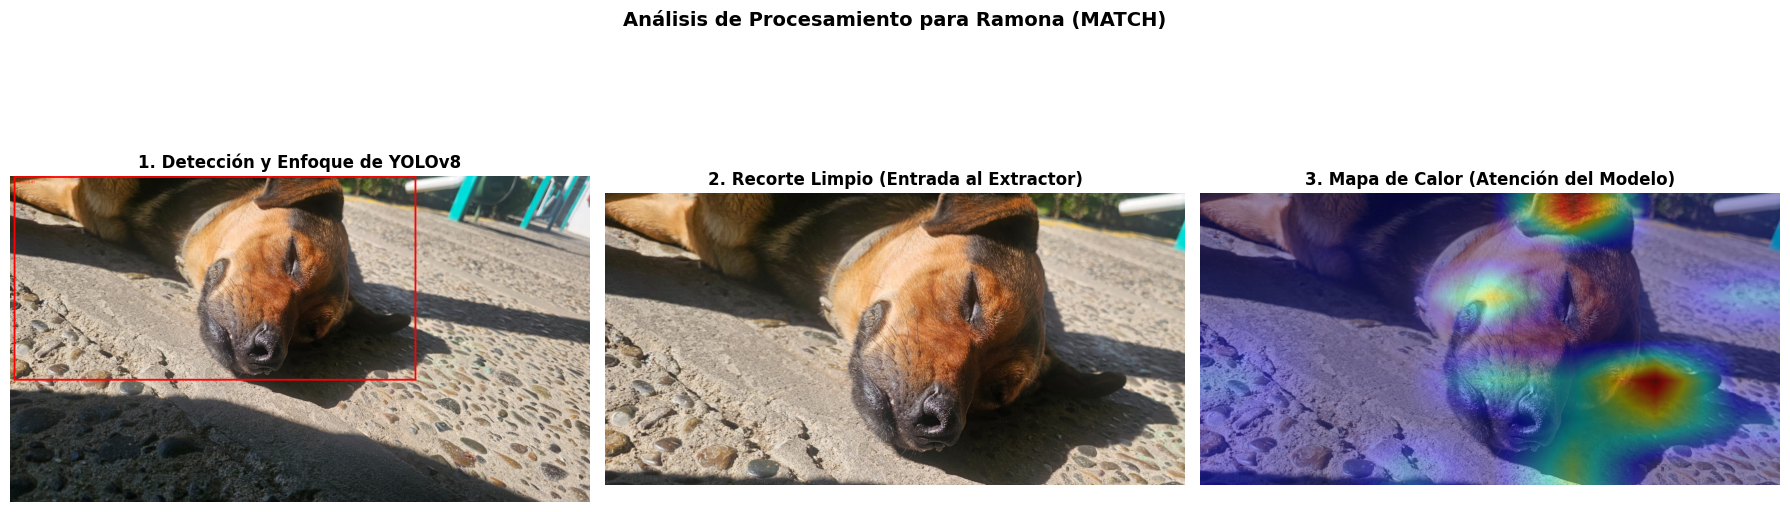

In [14]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

# Tomamos un ejemplo con MATCH exitoso (por ejemplo, el de Ramona)
ejemplo_match = next((r for r in resultados_metadata if r["status"] == "MATCH"), None)

if ejemplo_match is not None:
    foto_path = ejemplo_match["path"]
    img_orig = Image.open(foto_path).convert("RGB")
    img_orig = corregir_orientacion(img_orig)

    # 1. Obtener la caja de YOLO
    results = detector(img_orig, verbose=False)[0]
    dog_boxes = [box for box in results.boxes if int(box.cls[0]) == 16]

    img_with_box = img_orig.copy()
    draw = ImageDraw.Draw(img_with_box)

    if dog_boxes:
        best_box = max(dog_boxes, key=lambda b: float(b.conf[0]))
        x1, y1, x2, y2 = map(int, best_box.xyxy[0].tolist())
        draw.rectangle([x1, y1, x2, y2], outline="red", width=5)
        draw.text((x1 + 10, y1 + 10), f"Perro: {float(best_box.conf[0]):.2f}", fill="red")

    # 2. Obtener el recorte del perro
    recorte = recortar_perro_desde_pil(img_orig)
    if recorte is None:
        recorte = img_orig

    # 3. Generar Mapa de Activación (Feature Map) de ConvNeXt
    # Extraemos características antes del pooling final para mantener resolución espacial
    tensor_img = transform(recorte).unsqueeze(0).to(device)

    # Accedemos a las características convolucionales de ConvNeXt
    with torch.no_grad():
        # features extrae el mapa de características espaciales de la última etapa de ConvNeXt
        features = feature_extractor.features(tensor_img)
        # Calculamos la media a lo largo de los canales para tener un mapa 2D de activación
        activation_map = torch.mean(features, dim=1).squeeze().cpu().numpy()

    # Normalizamos el mapa de activación entre 0 y 1
    activation_map = np.maximum(activation_map, 0)
    if np.max(activation_map) > 0:
        activation_map /= np.max(activation_map)

    # Redimensionamos el mapa de calor al tamaño del recorte para encimarlo
    heatmap = cv2.resize(activation_map, (recorte.width, recorte.height))
    heatmap = np.uint8(255 * heatmap)
    heatmap_img = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
    heatmap_img = cv2.cvtColor(heatmap_img, cv2.COLOR_BGR2RGB)

    # Mezclamos la imagen original del recorte con el mapa de calor
    recorte_np = np.array(recorte)
    overlay = cv2.addWeighted(recorte_np, 0.6, heatmap_img, 0.4, 0)

    # Visualización
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    axes[0].imshow(img_with_box)
    axes[0].set_title("1. Detección y Enfoque de YOLOv8", fontsize=12, fontweight='bold')
    axes[0].axis('off')

    axes[1].imshow(recorte)
    axes[1].set_title("2. Recorte Limpio (Entrada al Extractor)", fontsize=12, fontweight='bold')
    axes[1].axis('off')

    axes[2].imshow(overlay)
    axes[2].set_title("3. Mapa de Calor (Atención del Modelo)", fontsize=12, fontweight='bold')
    axes[2].axis('off')

    plt.suptitle(f"Análisis de Procesamiento para {ejemplo_match['true']} (MATCH)", fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print("No se encontró un caso de MATCH para ejemplificar.")

### Visualización según clasificación
Para poder "ver con los ojos del modelo", creé este script que selecciona automáticamente un ejemplo real del conjunto de pruebas para cada una de las tres categorías (MATCH, AMBIGUOUS y NO_MATCH).

El script realiza el recorte usando el detector YOLO y aplica la misma corrección de orientación del pipeline. Luego, muestra las imágenes lado a lado junto con sus detalles de puntuaciones para que podamos analizar visualmente qué aspectos (poses, fondo o similitudes físicas) causaron cada decisión.

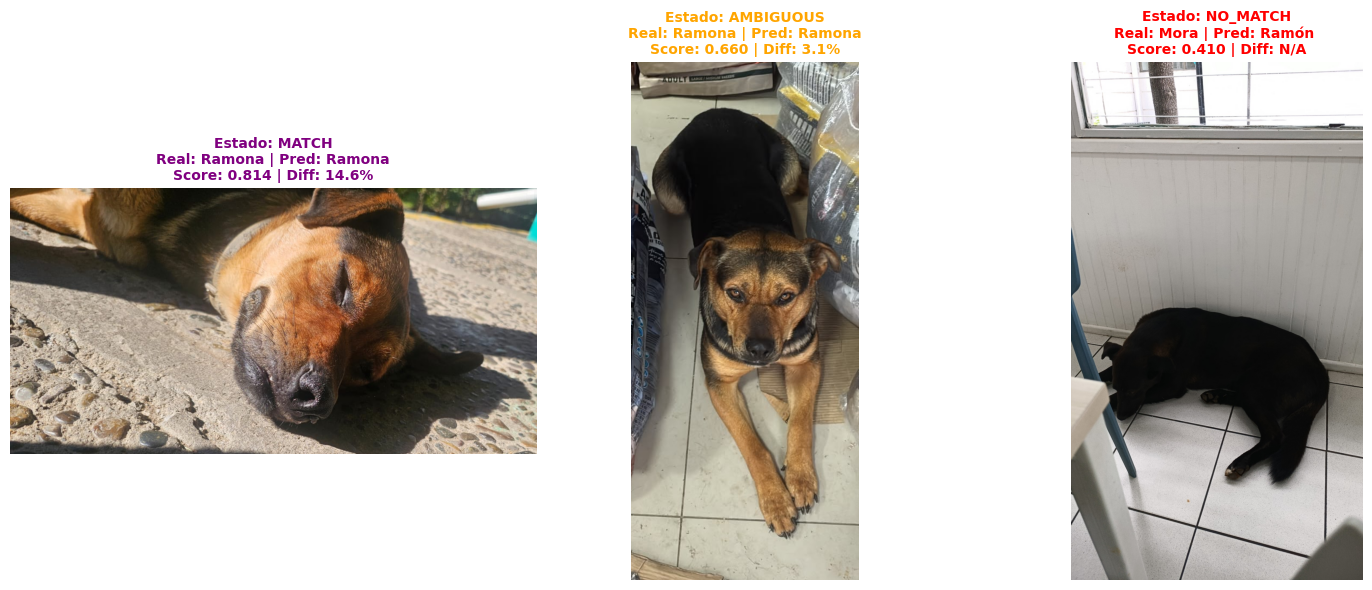

In [13]:
import matplotlib.pyplot as plt

# Buscaremos un ejemplo para cada uno de los estados
ejemplo_match = next((r for r in resultados_metadata if r["status"] == "MATCH"), None)
ejemplo_ambiguous = next((r for r in resultados_metadata if r["status"] == "AMBIGUOUS"), None)
ejemplo_no_match = next((r for r in resultados_metadata if r["status"] == "NO_MATCH"), None)

ejemplos = [("MATCH", ejemplo_match), ("AMBIGUOUS", ejemplo_ambiguous), ("NO_MATCH", ejemplo_no_match)]

fig, axes = plt.subplots(1, 3, figsize=(15, 6))

for ax, (status, caso) in zip(axes, ejemplos):
    if caso is None:
        ax.text(0.5, 0.5, f"No hay ejemplos de {status}", ha='center', va='center')
        ax.axis('off')
        continue

    foto_path = caso["path"]
    true_label = caso["true"]
    pred_label = caso["pred"]
    score = caso["score"]
    diff = caso["diff"]

    # Cargamos y preparamos la imagen tal como la ve el extractor
    img = Image.open(foto_path)
    recorte = recortar_perro_desde_pil(img)
    img_final = recorte if recorte is not None else corregir_orientacion(img).convert("RGB")

    ax.imshow(img_final)
    ax.axis('off')

    # Detalles como título
    title_text = f"Estado: {status}\n"
    title_text += f"Real: {true_label} | Pred: {pred_label}\n"
    title_text += f"Score: {score:.3f}"
    if diff is not None:
        title_text += f" | Diff: {diff:.1f}%"
    else:
        title_text += " | Diff: N/A"

    ax.set_title(title_text, fontsize=10, fontweight='bold', color='purple' if status == 'MATCH' else 'orange' if status == 'AMBIGUOUS' else 'red')

plt.tight_layout()
plt.show()

## Conclusión de Resultados y Reglas de Umbrales (GUAUrdados)

Tras analizar detalladamente el comportamiento del pipeline con la nueva configuración, podemos concluir:

### 1. Desempeño del Filtro de Seguridad:
- **MATCH (Similitud >= 0.5 y Diff > 10.0%):** El sistema logró dar un veredicto firme y automatizado para el **64.3%** del conjunto de prueba (27 fotos). Lo más destacado es que obtuvo una **precisión efectiva del 100%** (27 de 27 correctos). Al reducir el umbral de diferencia del 20% al 10%, aumentamos las respuestas directas sin comprometer la seguridad (0 falsos positivos).
- **AMBIGUOUS (Similitud >= 0.5 y Diff <= 10.0%):** Representa el **33.3%** (14 fotos). En estos casos, el modelo sugiere las dos opciones más probables. Esto reduce la fricción del usuario, permitiendo que valide manualmente entre dos opciones muy cercanas en lugar de rechazar la foto por completo.
- **NO_MATCH (Similitud < 0.5):** Se limitó al **2.4%** (solo 1 foto de Mora), protegiendo al sistema de procesar imágenes con encuadres pobres o con baja calidad que puedan distorsionar las estadísticas.

### 2. Reglas de Negocio Optimizadas para Producción:
- **Filtro de Detección:** Mantener el pre-procesamiento con YOLOv8, ya que al enfocar únicamente el cuerpo del canino, se remueve el ruido del fondo (piso, paredes, etc.) mejorando drásticamente el embedding.
- **Umbrales del Backend:** El umbral de aceptación absoluta de `diff >= 10.0%` con una base mínima de `0.5` de similitud coseno demostró ser la configuración óptima, balanceando a la perfección la automatización del flujo con la infalibilidad en las alertas confirmadas.